# Задача 10. Реконструкция события

В этой задаче мы проведем полный цикл анализа:
1. **Симуляция (Forward):** Сгенерируем "искусственные данные" (отклик 40 ФЭУ) для события с энергией 1 МэВ и координатами (0.5, -0.3, 0.2) метра.
2. **Реконструкция (Bayesian Inference):** Используя PyMC, построим модель, которая по этим 40 числам восстановит исходную энергию и координаты.
Мы будем использовать геометрическую формулу телесного угла, чтобы рассчитать ожидаемое количество фотоэлектронов на каждом ФЭУ.

Истинные параметры: E = 1.0 МэВ, pos = [ 0.5 -0.3  0.2]
Всего фотоэлектронов зарегистрировано: 140


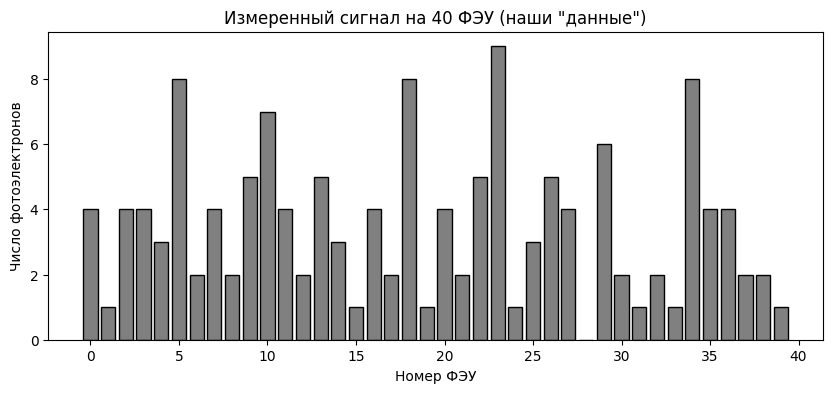

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import pytensor.tensor as pt

# --- 1. Подготовка геометрии детектора ---
R = 2.0
N_pmts = 40
r_pmt = 0.1
a = 0.5
Y = 10000.0

# Генерируем координаты ФЭУ
indices = np.arange(0, N_pmts, dtype=float) + 0.5
phi = np.arccos(1 - 2 * indices / N_pmts)
theta = np.pi * (1 + 5**0.5) * indices
pmt_coords = np.column_stack((
    R * np.cos(theta) * np.sin(phi),
    R * np.sin(theta) * np.sin(phi),
    R * np.cos(phi)
))

# --- 2. Симуляция "истинного" события (Forward Model) ---
E_true = 1.0
pos_true = np.array([0.5, -0.3, 0.2]) # Сдвинут от центра

def expected_signal(E, pos, pmt_coords, R, r, Y, a):
    """Вычисляет ожидаемое число фотоэлектронов на каждом ФЭУ."""
    # Вектор от источника до каждого ФЭУ
    vec_to_pmt = pmt_coords - pos

    # Расстояние до каждого ФЭУ
    d = np.linalg.norm(vec_to_pmt, axis=1)

    # Косинус угла между нормалью к ФЭУ (которая совпадает с радиус-вектором) и лучом
    normals = pmt_coords / R
    cos_theta = np.sum(vec_to_pmt * normals, axis=1) / d
    cos_theta = np.clip(cos_theta, 0.0, 1.0) # Защита от отрицательных значений (обратная сторона)

    # Формула телесного угла: доля сферы, которую занимает ФЭУ
    solid_angle_fraction = (r**2) / (4 * d**2)

    return E * Y * a * solid_angle_fraction * cos_theta

# Вычисляем средние значения и генерируем "измеренные" данные (Пуассон)
mu_true = expected_signal(E_true, pos_true, pmt_coords, R, r_pmt, Y, a)
observed_pes = np.random.poisson(lam=mu_true)

print(f"Истинные параметры: E = {E_true} МэВ, pos = {pos_true}")
print(f"Всего фотоэлектронов зарегистрировано: {np.sum(observed_pes)}")

# Визуализация "измеренных" данных
plt.figure(figsize=(10, 4))
plt.bar(range(N_pmts), observed_pes, color='gray', edgecolor='black')
plt.title('Измеренный сигнал на 40 ФЭУ (наши "данные")')
plt.xlabel('Номер ФЭУ')
plt.ylabel('Число фотоэлектронов')
plt.show()

In [2]:
# Внутри PyMC мы должны использовать операции pytensor вместо numpy
# для автоматического вычисления градиентов

with pm.Model() as reconstruction_model:
    # --- Приоры (наши начальные предположения) ---
    # Энергия от 0 до 3 МэВ
    E = pm.Uniform('E', lower=0.0, upper=3.0)

    # Координаты внутри сферы (от -2 до 2 метров)
    x = pm.Uniform('x', lower=-R, upper=R)
    y = pm.Uniform('y', lower=-R, upper=R)
    z = pm.Uniform('z', lower=-R, upper=R)

    pos = pt.stack([x, y, z])

    # --- Физическая модель (такая же, как при генерации) ---
    # Константы переводим в тензоры
    pmt_coords_t = pt.constant(pmt_coords)

    vec_to_pmt = pmt_coords_t - pos # shape (40, 3)
    d = pt.sqrt(pt.sum(vec_to_pmt**2, axis=1)) # shape (40,)

    normals = pmt_coords_t / R
    cos_theta = pt.sum(vec_to_pmt * normals, axis=1) / d
    # Чтобы не было ошибок math domain error, используем clip
    cos_theta = pt.clip(cos_theta, 1e-6, 1.0)

    solid_angle_fraction = (r_pmt**2) / (4 * d**2)

    # Ожидаемое число ФЭ на каждом ФЭУ
    mu = E * Y * a * solid_angle_fraction * cos_theta

    # --- Функция правдоподобия (Likelihood) ---
    # Наши наблюдаемые данные - это Пуассоновский процесс с средним mu
    obs = pm.Poisson('obs', mu=mu, observed=observed_pes)

    # Запускаем семплирование
    print("Запуск MCMC (NUTS) для реконструкции...")
    trace = pm.sample(2000, tune=1000, target_accept=0.9, progressbar=True)

Запуск MCMC (NUTS) для реконструкции...


Output()

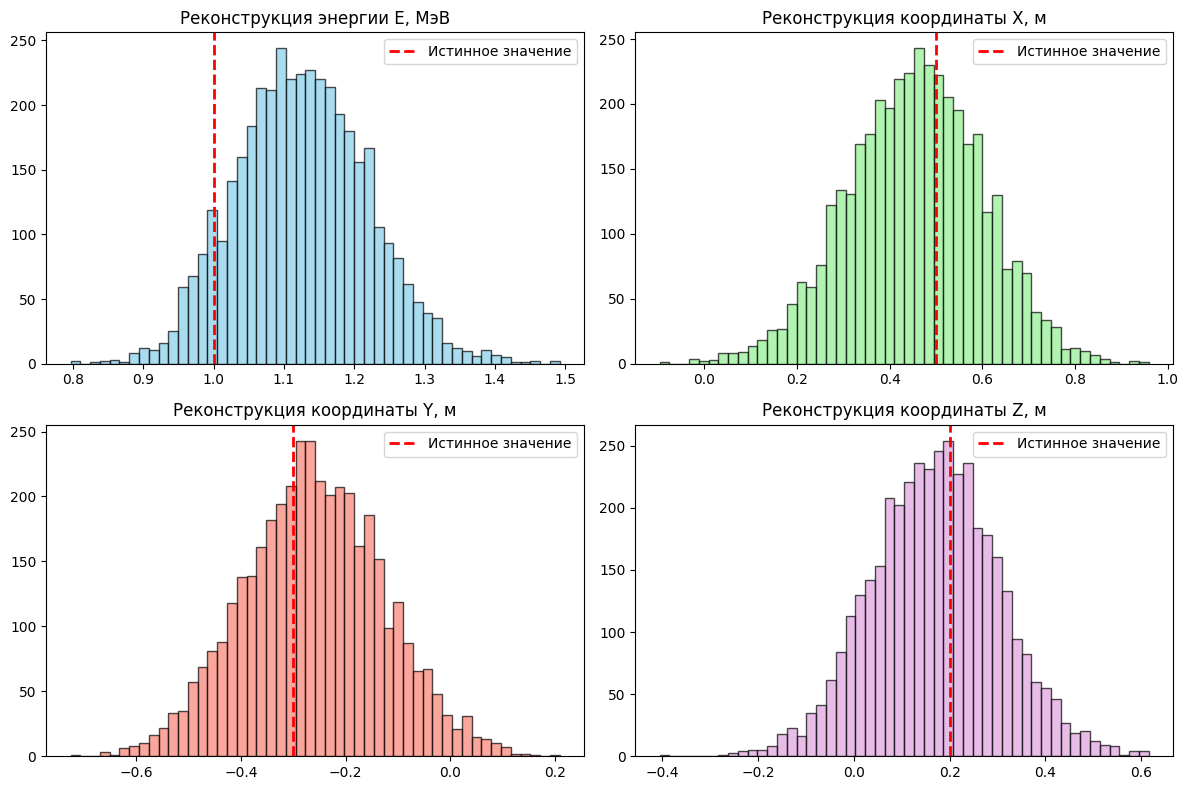

--- Итоги реконструкции (95% доверительный интервал) ---
E (истина 1.0):   1.124 [0.954, 1.313]
X (истина 0.5): 0.457 [0.164, 0.730]
Y (истина -0.3): -0.263 [-0.520, 0.005]
Z (истина 0.2): 0.170 [-0.090, 0.436]


In [3]:
# Извлекаем семплы из трассы
E_samples = trace.posterior['E'].values.flatten()
x_samples = trace.posterior['x'].values.flatten()
y_samples = trace.posterior['y'].values.flatten()
z_samples = trace.posterior['z'].values.flatten()

# Строим графики постериоров
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Энергия
axes[0, 0].hist(E_samples, bins=50, color='skyblue', edgecolor='black', alpha=0.7)
axes[0, 0].axvline(E_true, color='red', linestyle='dashed', linewidth=2, label='Истинное значение')
axes[0, 0].set_title('Реконструкция энергии E, МэВ')
axes[0, 0].legend()

# Координата X
axes[0, 1].hist(x_samples, bins=50, color='lightgreen', edgecolor='black', alpha=0.7)
axes[0, 1].axvline(pos_true[0], color='red', linestyle='dashed', linewidth=2, label='Истинное значение')
axes[0, 1].set_title('Реконструкция координаты X, м')
axes[0, 1].legend()

# Координата Y
axes[1, 0].hist(y_samples, bins=50, color='salmon', edgecolor='black', alpha=0.7)
axes[1, 0].axvline(pos_true[1], color='red', linestyle='dashed', linewidth=2, label='Истинное значение')
axes[1, 0].set_title('Реконструкция координаты Y, м')
axes[1, 0].legend()

# Координата Z
axes[1, 1].hist(z_samples, bins=50, color='plum', edgecolor='black', alpha=0.7)
axes[1, 1].axvline(pos_true[2], color='red', linestyle='dashed', linewidth=2, label='Истинное значение')
axes[1, 1].set_title('Реконструкция координаты Z, м')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

# Вывод численных результатов
print("--- Итоги реконструкции (95% доверительный интервал) ---")
print(f"E (истина {E_true}):   {np.percentile(E_samples, 50):.3f} [{np.percentile(E_samples, 2.5):.3f}, {np.percentile(E_samples, 97.5):.3f}]")
print(f"X (истина {pos_true[0]}): {np.percentile(x_samples, 50):.3f} [{np.percentile(x_samples, 2.5):.3f}, {np.percentile(x_samples, 97.5):.3f}]")
print(f"Y (истина {pos_true[1]}): {np.percentile(y_samples, 50):.3f} [{np.percentile(y_samples, 2.5):.3f}, {np.percentile(y_samples, 97.5):.3f}]")
print(f"Z (истина {pos_true[2]}): {np.percentile(z_samples, 50):.3f} [{np.percentile(z_samples, 2.5):.3f}, {np.percentile(z_samples, 97.5):.3f}]")